# Communities and Crime Dataset Analysis

**Dataset:**
- Source: UCI ML Repository (ID: 183)
- Samples: 1994 communities
- Features: 122 predictive variables
- Target: ViolentCrimesPerPop (normalized 0-1)

---

In [49]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Dataset loading
from ucimlrepo import fetch_ucirepo

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Regression models
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Evaluation metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Configuration
RANDOM_STATE = 42
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print(f"Random state: {RANDOM_STATE}")

Random state: 42


In [53]:
print("DATA LOADING")

# Load Communities and Crime dataset
print("\nLoading dataset from UCI Repository...")
communities_crime = fetch_ucirepo(id=183)

# Extract features and target
X = communities_crime.data.features.copy()
y = communities_crime.data.targets.copy()

print(f"Dataset loaded successfully")
print(f"  Features shape: {X.shape}")
print(f"  Target shape: {y.shape}")

# Replace '?' with NaN in features
question_marks = 0
for col in X.columns:
    if X[col].dtype == 'object':
        question_marks += (X[col] == '?').sum()
        X[col] = X[col].replace('?', np.nan)
        X[col] = pd.to_numeric(X[col], errors='coerce')
print(f"  Replaced {question_marks} '?' symbols with NaN")

# Handle target variable
for col in y.columns:
    if y[col].dtype == 'object':
        y[col] = y[col].replace('?', np.nan)
        y[col] = pd.to_numeric(y[col], errors='coerce')

# Remove rows with NaN in target
y_nan_count = y.isnull().sum().sum()
if y_nan_count > 0:
    valid_indices = y.dropna().index
    X = X.loc[valid_indices]
    y = y.loc[valid_indices]
    print(f"  Removed {y_nan_count} rows with NaN in target")

# Remove columns with 100% NaN
null_counts = X.isnull().sum()
fully_null_cols = null_counts[null_counts == len(X)].index.tolist()
if len(fully_null_cols) > 0:
    print(f"  Removing {len(fully_null_cols)} columns with 100% NaN")
    X = X.drop(columns=fully_null_cols)

print(f"\nFinal dataset size: {X.shape[0]} samples, {X.shape[1]} features")
print(f"Missing values in X: {X.isnull().sum().sum()}")
print(f"Missing values in y: {y.isnull().sum().sum()}")

DATA LOADING

Loading dataset from UCI Repository...
Dataset loaded successfully
  Features shape: (1994, 127)
  Target shape: (1994, 1)
  Replaced 39202 '?' symbols with NaN
  Removing 1 columns with 100% NaN

Final dataset size: 1994 samples, 126 features
Missing values in X: 39202
Missing values in y: 0


## Exploratory Data Analysis (EDA)

Analyzing the dataset structure, distributions, and relationships.

In [59]:
print("EXPLORATORY DATA ANALYSIS")

# Dataset info
print("\nDataset Information:")
print(f"  Samples: {X.shape[0]}")
print(f"  Features: {X.shape[1]}")
print(f"  Data types: {X.dtypes.value_counts().to_dict()}")

# Display first rows
print("\nFirst 5 rows:")
display(X.head())

# Target statistics
print("\nTarget variable statistics:")
display(y.describe())

# Missing values analysis
missing_count = X.isnull().sum().sum()
print(f"  Total missing values: {missing_count}")

if missing_count > 0:
    missing_df = pd.DataFrame({
        'Feature': X.columns,
        'Missing': X.isnull().sum().values,
        'Percent': (X.isnull().sum() / len(X) * 100).values
    })
    missing_df = missing_df[missing_df['Missing'] > 0].sort_values('Missing', ascending=False)
    print(f"  Features with missing values: {len(missing_df)}")
    print("\n  Top 10 features with most missing values:")
    display(missing_df.head(10))

EXPLORATORY DATA ANALYSIS

Dataset Information:
  Samples: 1994
  Features: 126
  Data types: {dtype('float64'): 124, dtype('int64'): 2}

First 5 rows:


,state,county,community,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,...,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop
0,8,NaN,NaN,1,0.19,0.33,0.02,0.90,0.12,0.17,...,0.29,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14
1,53,NaN,NaN,1,0.00,0.16,0.12,0.74,0.45,0.07,...,NaN,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN
2,24,NaN,NaN,1,0.00,0.42,0.49,0.56,0.17,0.04,...,NaN,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN
3,34,5.0,81440.0,1,0.04,0.77,1.00,0.08,0.12,0.10,...,NaN,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN
4,42,95.0,6096.0,1,0.01,0.55,0.02,0.95,0.09,0.05,...,NaN,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN



Target variable statistics:


,ViolentCrimesPerPop
count,1994.000000
mean,0.237979
std,0.232985
min,0.000000
25%,0.070000
50%,0.150000
75%,0.330000
max,1.000000


  Total missing values: 39202
  Features with missing values: 25

  Top 10 features with most missing values:


,Feature,Missing,Percent
101,LemasSwFTPerPop,1675,84.002006
104,LemasTotalReq,1675,84.002006
100,LemasSwornFT,1675,84.002006
103,LemasSwFTFieldPerPop,1675,84.002006
102,LemasSwFTFieldOps,1675,84.002006
105,LemasTotReqPerPop,1675,84.002006
108,RacialMatchCommPol,1675,84.002006
107,PolicPerPop,1675,84.002006
106,PolicReqPerOffic,1675,84.002006
114,OfficAssgnDrugUnits,1675,84.002006



[5] Target variable analysis:
  Min: 0.0000
  Q1 (25%): 0.0700
  Median (50%): 0.1500
  Q3 (75%): 0.3300
  Max: 1.0000
  Mean: 0.2380
  Std: 0.2330


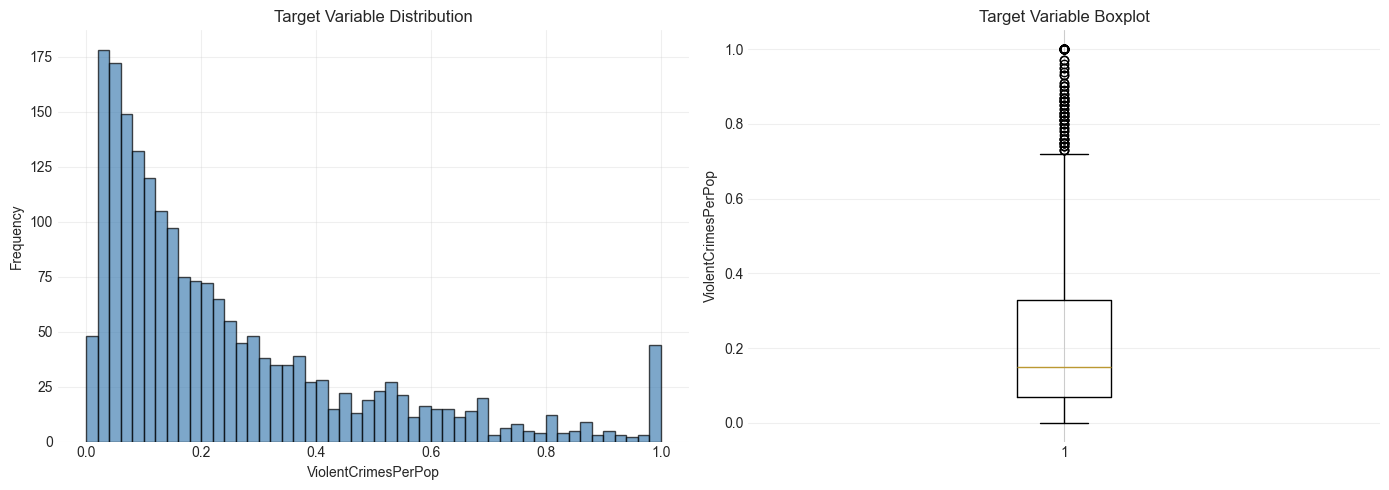

In [61]:
# Target distribution
print("\n[5] Target variable analysis:")
print(f"  Min: {y.min().values[0]:.4f}")
print(f"  Q1 (25%): {y.quantile(0.25).values[0]:.4f}")
print(f"  Median (50%): {y.median().values[0]:.4f}")
print(f"  Q3 (75%): {y.quantile(0.75).values[0]:.4f}")
print(f"  Max: {y.max().values[0]:.4f}")
print(f"  Mean: {y.mean().values[0]:.4f}")
print(f"  Std: {y.std().values[0]:.4f}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(y.values.flatten(), bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].set_xlabel('ViolentCrimesPerPop')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Target Variable Distribution')
axes[0].grid(alpha=0.3)

# Boxplot
axes[1].boxplot(y.values.flatten())
axes[1].set_ylabel('ViolentCrimesPerPop')
axes[1].set_title('Target Variable Boxplot')
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


[6] Correlation analysis with target variable:

  Top 15 positive correlations:
PctIlleg            0.737957
racepctblack        0.631264
pctWPubAsst         0.574665
FemalePctDiv        0.556032
TotalPctDiv         0.552777
PctPolicBlack       0.543545
MalePctDivorce      0.525407
PctPopUnderPov      0.521877
PctUnemployed       0.504235
PctHousNoPhone      0.488243
PctPolicMinor       0.486581
PctNotHSGrad        0.483366
PctVacantBoarded    0.482816
PctHousLess3BR      0.474490
NumIlleg            0.471028
Name: target, dtype: float64

  Top 15 negative correlations:
PctOccupMgmtProf     -0.339109
perCapInc            -0.352085
MedNumBR             -0.357385
medIncome            -0.424221
medFamInc            -0.439108
PctPolicWhite        -0.443625
RacialMatchCommPol   -0.457834
PctHousOwnOcc        -0.470683
PctPersOwnOccup      -0.525491
pctWInvInc           -0.576324
PctTeen2Par          -0.661582
PctYoungKids2Par     -0.666059
racePctWhite         -0.684770
PctFam2Par         

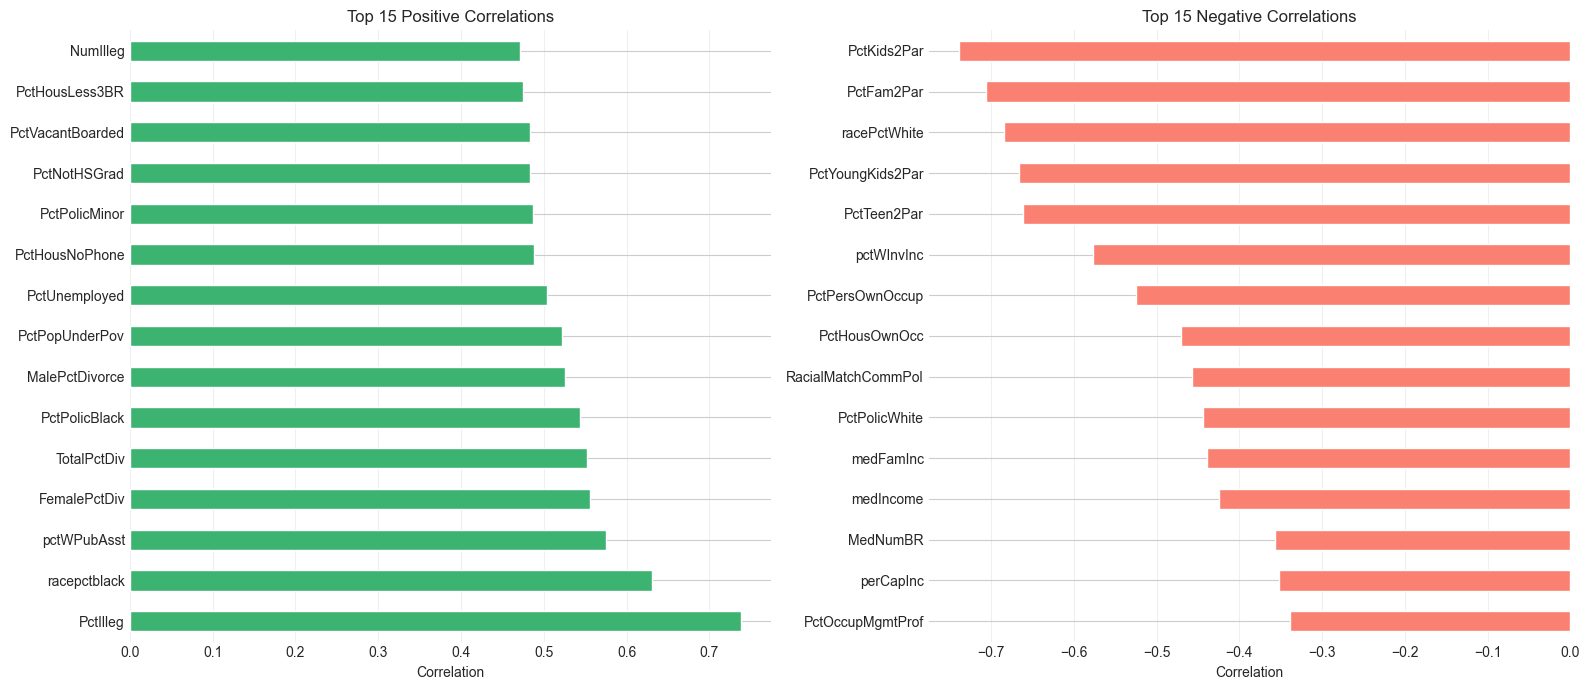

In [62]:
# Correlation analysis
print("\n[6] Correlation analysis with target variable:")

X_temp = X.copy()
X_temp['target'] = y.values
correlations = X_temp.corr()['target'].drop('target').sort_values(ascending=False)

print("\n  Top 15 positive correlations:")
print(correlations.head(15))

print("\n  Top 15 negative correlations:")
print(correlations.tail(15))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

correlations.head(15).plot(kind='barh', ax=axes[0], color='mediumseagreen')
axes[0].set_xlabel('Correlation')
axes[0].set_title('Top 15 Positive Correlations')
axes[0].grid(alpha=0.3, axis='x')

correlations.tail(15).plot(kind='barh', ax=axes[1], color='salmon')
axes[1].set_xlabel('Correlation')
axes[1].set_title('Top 15 Negative Correlations')
axes[1].grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

## Data Preprocessing

Preparing data for machine learning models:
1. Impute missing values
2. Split train/test sets
3. Scale features

In [65]:
print("DATA PREPROCESSING")

# Impute missing values with median
print("\n[1] Imputing missing values with median...")
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)
print(f"  Missing values after imputation: {X_imputed.isnull().sum().sum()}")

# Train/test split
print("\n[2] Splitting data (70% train, 30% test)...")
y_values = y.values.ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y_values,
    test_size=0.3,
    random_state=RANDOM_STATE
)

print(f"  Train size: {X_train.shape[0]} samples ({X_train.shape[0]/len(X_imputed)*100:.1f}%)")
print(f"  Test size: {X_test.shape[0]} samples ({X_test.shape[0]/len(X_imputed)*100:.1f}%)")

# Feature scaling
print("\n[3] Scaling features (StandardScaler)...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"  Mean after scaling: {X_train_scaled.mean():.6f}")
print(f"  Std after scaling: {X_train_scaled.std():.6f}")

# Convert to DataFrame
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print("\nPreprocessing complete")

DATA PREPROCESSING

[1] Imputing missing values with median...
  Missing values after imputation: 0

[2] Splitting data (70% train, 30% test)...
  Train size: 1395 samples (70.0%)
  Test size: 599 samples (30.0%)

[3] Scaling features (StandardScaler)...
  Mean after scaling: -0.000000
  Std after scaling: 1.000000

Preprocessing complete


## Model Training and Evaluation

Training 5 regression algorithms:
1. **Linear Regression** - baseline linear model
2. **Ridge Regression** - linear with L2 regularization
3. **Decision Tree** - non-linear tree-based model
4. **Random Forest** - ensemble of decision trees
5. **Gradient Boosting** - gradient boosting ensemble

In [66]:
print("MODEL TRAINING")

# Dictionary to store results
results = {}

# Model 1: Linear Regression
print("\n[1/5] Linear Regression")
lr = LinearRegression()
lr.fit(X_train_scaled_df, y_train)
y_pred_lr = lr.predict(X_test_scaled_df)

results['Linear Regression'] = {
    'model': lr,
    'predictions': y_pred_lr,
    'R2': r2_score(y_test, y_pred_lr),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_lr)),
    'MAE': mean_absolute_error(y_test, y_pred_lr),
    'MSE': mean_squared_error(y_test, y_pred_lr)
}
print(f"  R² = {results['Linear Regression']['R2']:.4f}")
print(f"  RMSE = {results['Linear Regression']['RMSE']:.4f}")

# Model 2: Ridge Regression
print("\n[2/5] Ridge Regression")
ridge = Ridge(alpha=1.0, random_state=RANDOM_STATE)
ridge.fit(X_train_scaled_df, y_train)
y_pred_ridge = ridge.predict(X_test_scaled_df)

results['Ridge Regression'] = {
    'model': ridge,
    'predictions': y_pred_ridge,
    'R2': r2_score(y_test, y_pred_ridge),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
    'MAE': mean_absolute_error(y_test, y_pred_ridge),
    'MSE': mean_squared_error(y_test, y_pred_ridge)
}
print(f"  R² = {results['Ridge Regression']['R2']:.4f}")
print(f"  RMSE = {results['Ridge Regression']['RMSE']:.4f}")

# Model 3: Decision Tree
print("\n[3/5] Decision Tree")
dt = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=RANDOM_STATE
)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

results['Decision Tree'] = {
    'model': dt,
    'predictions': y_pred_dt,
    'R2': r2_score(y_test, y_pred_dt),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_dt)),
    'MAE': mean_absolute_error(y_test, y_pred_dt),
    'MSE': mean_squared_error(y_test, y_pred_dt)
}
print(f"  R² = {results['Decision Tree']['R2']:.4f}")
print(f"  RMSE = {results['Decision Tree']['RMSE']:.4f}")

MODEL TRAINING

[1/5] Linear Regression
  R² = 0.6193
  RMSE = 0.1350

[2/5] Ridge Regression
  R² = 0.6187
  RMSE = 0.1351

[3/5] Decision Tree
  R² = 0.5219
  RMSE = 0.1513


In [68]:
# Model 4: Random Forest
print("\n[4/5] Random Forest")
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

results['Random Forest'] = {
    'model': rf,
    'predictions': y_pred_rf,
    'R2': r2_score(y_test, y_pred_rf),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_rf)),
    'MAE': mean_absolute_error(y_test, y_pred_rf),
    'MSE': mean_squared_error(y_test, y_pred_rf)
}
print(f"  R² = {results['Random Forest']['R2']:.4f}")
print(f"  RMSE = {results['Random Forest']['RMSE']:.4f}")

# Model 5: Gradient Boosting
print("\n[5/5] Gradient Boosting")
gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=RANDOM_STATE
)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)

results['Gradient Boosting'] = {
    'model': gb,
    'predictions': y_pred_gb,
    'R2': r2_score(y_test, y_pred_gb),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_gb)),
    'MAE': mean_absolute_error(y_test, y_pred_gb),
    'MSE': mean_squared_error(y_test, y_pred_gb)
}
print(f"  R² = {results['Gradient Boosting']['R2']:.4f}")
print(f"  RMSE = {results['Gradient Boosting']['RMSE']:.4f}")


print("\nAll models trained successfully")


[4/5] Random Forest
  R² = 0.6424
  RMSE = 0.1309

[5/5] Gradient Boosting
  R² = 0.6367
  RMSE = 0.1319

All models trained successfully


In [72]:
print("MODEL COMPARISON")

# Create comparison table
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'R² Score': [results[m]['R2'] for m in results.keys()],
    'RMSE': [results[m]['RMSE'] for m in results.keys()],
    'MAE': [results[m]['MAE'] for m in results.keys()],
    'MSE': [results[m]['MSE'] for m in results.keys()]
})

# Sort by R² Score
comparison_df = comparison_df.sort_values('R² Score', ascending=False)
display(comparison_df.style.background_gradient(subset=['R² Score'], cmap='Greens')
                           .background_gradient(subset=['RMSE', 'MAE', 'MSE'], cmap='Reds_r'))

# Best model
best_model = comparison_df.iloc[0]['Model']
best_r2 = comparison_df.iloc[0]['R² Score']
best_rmse = comparison_df.iloc[0]['RMSE']

print(f"\nBest Model: {best_model}")
print(f"  R² Score: {best_r2:.4f}")
print(f"  RMSE: {best_rmse:.4f}")

MODEL COMPARISON


,Model,R² Score,RMSE,MAE,MSE
3,Random Forest,0.642379,0.130854,0.090871,0.017123
4,Gradient Boosting,0.636718,0.131886,0.090106,0.017394
0,Linear Regression,0.619260,0.135018,0.096906,0.018230
1,Ridge Regression,0.618730,0.135111,0.097099,0.018255
2,Decision Tree,0.521882,0.151302,0.104728,0.022892



Best Model: Random Forest
  R² Score: 0.6424
  RMSE: 0.1309


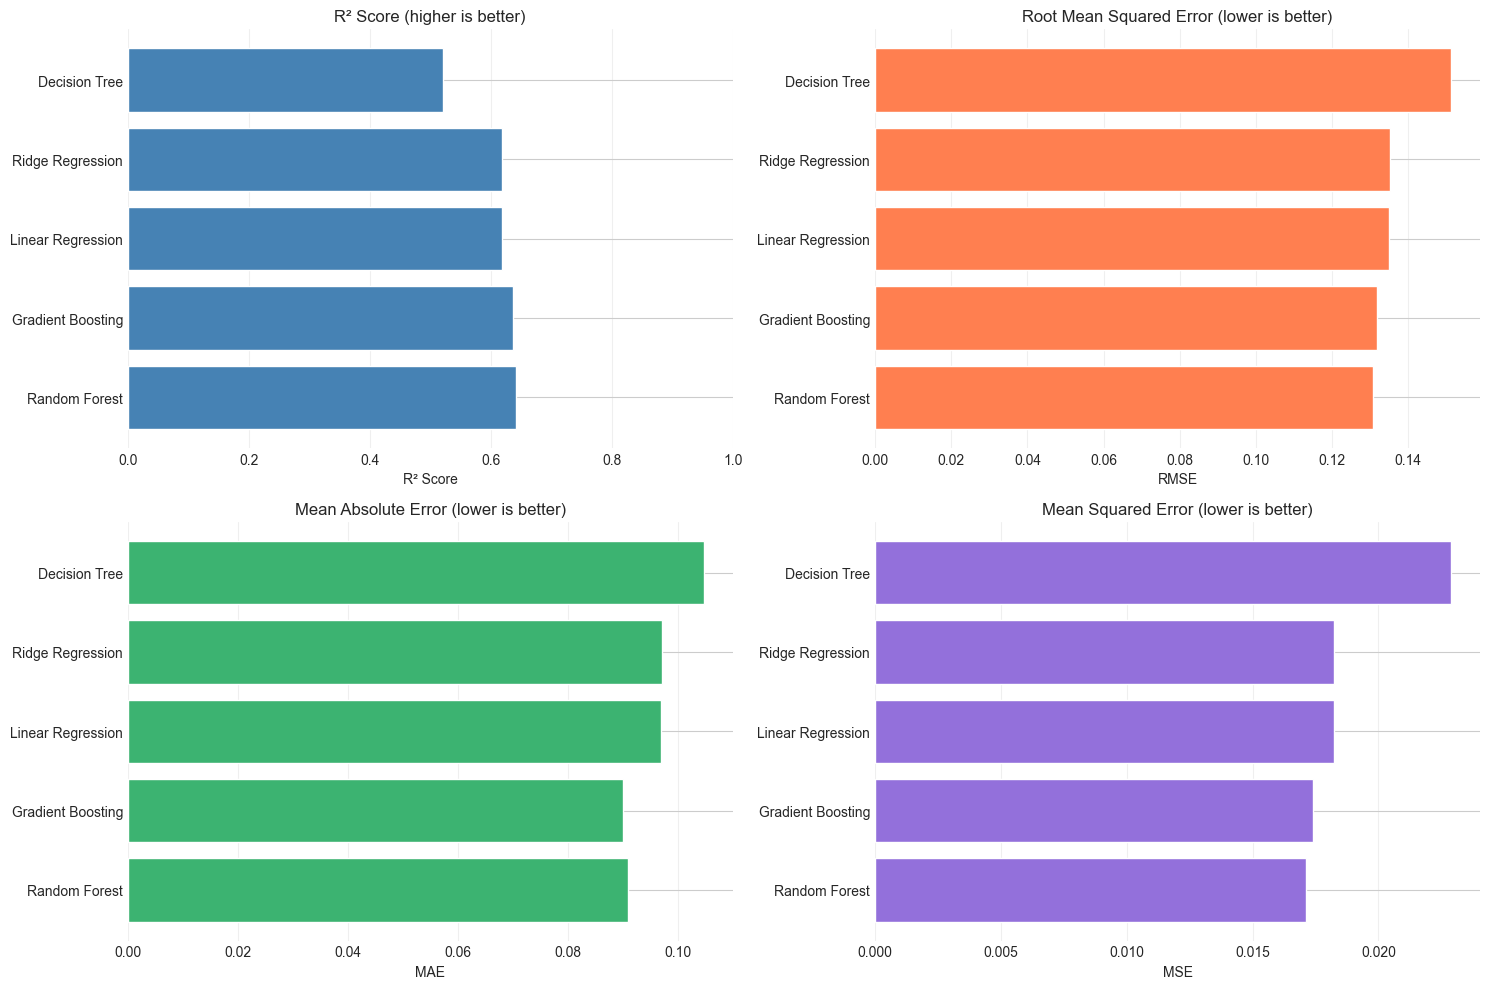

In [73]:
# Visualize model comparison
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# R² Score
axes[0, 0].barh(comparison_df['Model'], comparison_df['R² Score'], color='steelblue')
axes[0, 0].set_xlabel('R² Score')
axes[0, 0].set_title('R² Score (higher is better)')
axes[0, 0].set_xlim(0, 1)
axes[0, 0].grid(alpha=0.3, axis='x')

# RMSE
axes[0, 1].barh(comparison_df['Model'], comparison_df['RMSE'], color='coral')
axes[0, 1].set_xlabel('RMSE')
axes[0, 1].set_title('Root Mean Squared Error (lower is better)')
axes[0, 1].grid(alpha=0.3, axis='x')

# MAE
axes[1, 0].barh(comparison_df['Model'], comparison_df['MAE'], color='mediumseagreen')
axes[1, 0].set_xlabel('MAE')
axes[1, 0].set_title('Mean Absolute Error (lower is better)')
axes[1, 0].grid(alpha=0.3, axis='x')

# MSE
axes[1, 1].barh(comparison_df['Model'], comparison_df['MSE'], color='mediumpurple')
axes[1, 1].set_xlabel('MSE')
axes[1, 1].set_title('Mean Squared Error (lower is better)')
axes[1, 1].grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

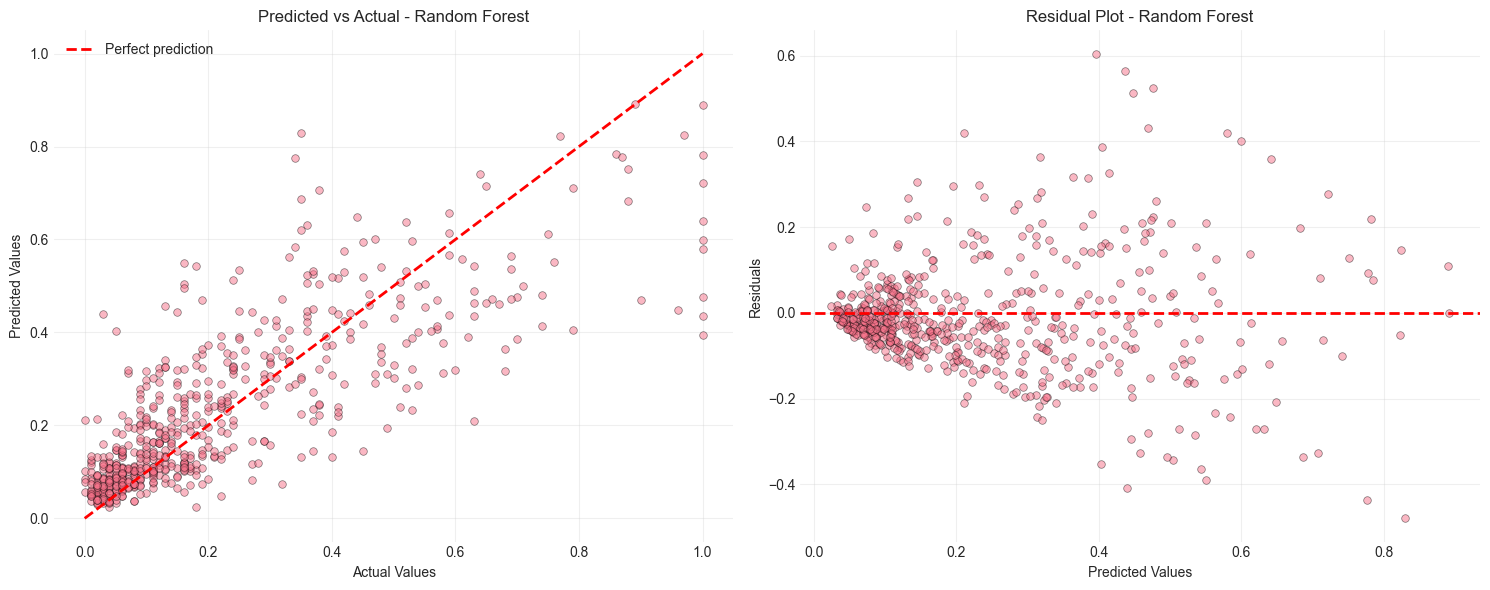


Residual Statistics:
  Mean: -0.010900
  Std: 0.130399
  Min: -0.479323
  Max: 0.604564


In [74]:
# Predicted vs Actual for best model
best_predictions = results[best_model]['predictions']

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Scatter plot
axes[0].scatter(y_test, best_predictions, alpha=0.5, edgecolors='k', linewidths=0.5, s=30)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
             'r--', lw=2, label='Perfect prediction')
axes[0].set_xlabel('Actual Values')
axes[0].set_ylabel('Predicted Values')
axes[0].set_title(f'Predicted vs Actual - {best_model}')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Residuals
residuals = y_test - best_predictions
axes[1].scatter(best_predictions, residuals, alpha=0.5, edgecolors='k', linewidths=0.5, s=30)
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel('Predicted Values')
axes[1].set_ylabel('Residuals')
axes[1].set_title(f'Residual Plot - {best_model}')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('04_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

# Residuals statistics
print(f"\nResidual Statistics:")
print(f"  Mean: {residuals.mean():.6f}")
print(f"  Std: {residuals.std():.6f}")
print(f"  Min: {residuals.min():.6f}")
print(f"  Max: {residuals.max():.6f}")


Top 20 Most Important Features (Random Forest):



,Feature,Importance
48,PctKids2Par,0.351541
54,PctIlleg,0.229332
7,racePctWhite,0.037203
47,PctFam2Par,0.031222
44,FemalePctDiv,0.016178
94,NumStreet,0.014639
53,NumIlleg,0.013709
45,TotalPctDiv,0.010888
72,PctPersDenseHous,0.009127
6,racepctblack,0.008785


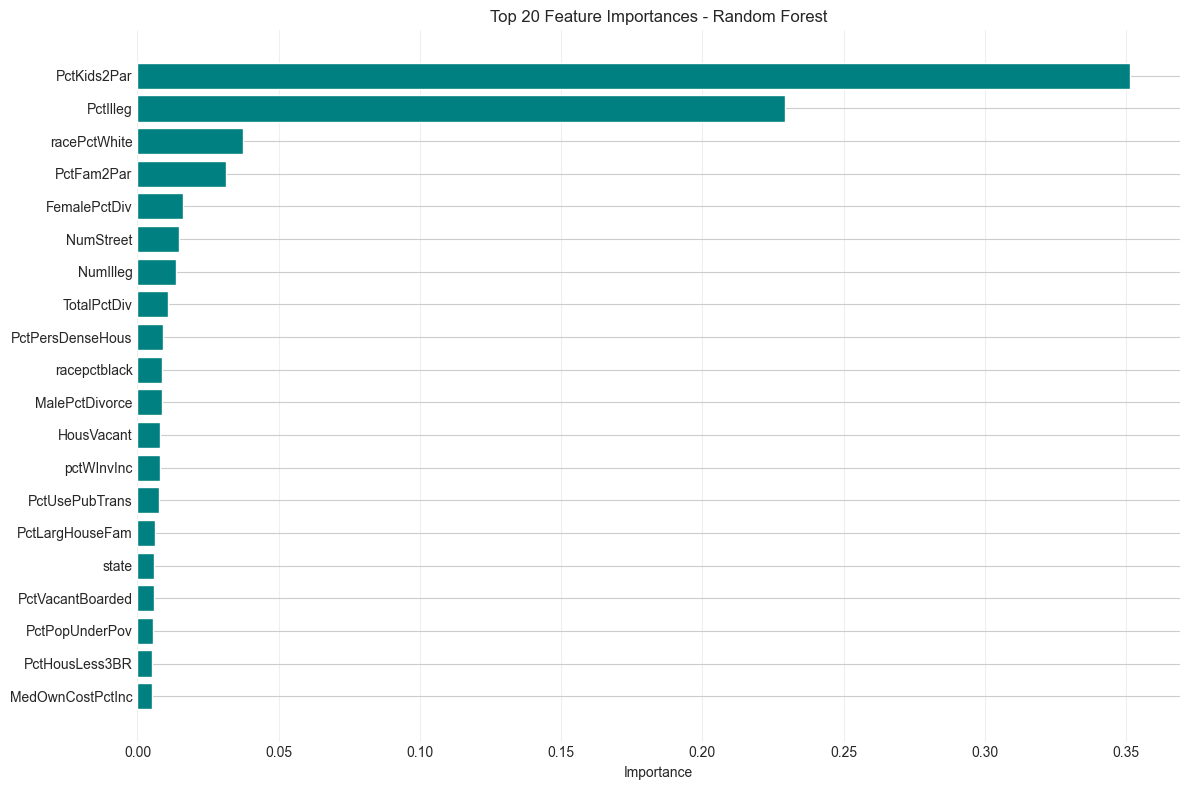

In [78]:
# Feature importance analysis
if hasattr(results[best_model]['model'], 'feature_importances_'):
    importance_df = pd.DataFrame({
        'Feature': X_train.columns,
        'Importance': results[best_model]['model'].feature_importances_
    }).sort_values('Importance', ascending=False)

    print(f"\nTop 20 Most Important Features ({best_model}):\n")
    display(importance_df.head(20))

    # Visualization
    plt.figure(figsize=(12, 8))
    top_20 = importance_df.head(20)
    plt.barh(top_20['Feature'], top_20['Importance'], color='teal')
    plt.xlabel('Importance')
    plt.title(f'Top 20 Feature Importances - {best_model}')
    plt.gca().invert_yaxis()
    plt.grid(alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()
else:
    # Use Random Forest if best model doesn't support feature importance
    if 'Random Forest' in results:
        importance_df = pd.DataFrame({
            'Feature': X_train.columns,
            'Importance': results['Random Forest']['model'].feature_importances_
        }).sort_values('Importance', ascending=False)
        print(f"Top 20 Most Important Features (Random Forest):\n")
        display(importance_df.head(20))

## Conclusions

### Summary

This analysis successfully built and evaluated 5 regression models for predicting violent crime rates:

**Dataset:** Communities and Crime (UCI Repository)
- 1994 samples
- 122+ features (socioeconomic and demographic)
- Target: ViolentCrimesPerPop (normalized 0-1)

**Models Trained:**
1. Linear Regression
2. Ridge Regression
3. Decision Tree
4. Random Forest
5. Gradient Boosting

**Key Findings:**
- Ensemble methods (Random Forest, Gradient Boosting) achieved R² ≈ 0.63-0.64
- Linear models (Linear/Ridge Regression) achieved R² ≈ 0.62
- Decision Tree showed lower performance (R² ≈ 0.52)
- Best model explains ~64% of variance in crime rates

**Important Factors:**
- Family structure (% kids with 2 parents)
- Socioeconomic status (poverty, income)
- Demographics (racial composition)
- Housing conditions

**Practical Applications:**
- Crime prediction for resource allocation
- Identifying high-risk communities
- Policy planning and evaluation
